# **MÓDULO 13**
# Projeto - Fundamentos da Descoberta de Dados

Nesse projeto trabalharemos com a base de dados de produtos de um supermercado do Chile.
A ideia é aplicar os conceitos estatísticos vistos no último módulo, mais os conceitos de visualização de dados através de gráficos, e finalizar publicando no GitHub.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px

os.makedirs('graficos', exist_ok=True)

Leitura dos dados do arquivo CSV (nessa versão do arquivo o separador é vírgula):

In [2]:
df = pd.read_csv('MODULO7_PROJETOFINAL_BASE_SUPERMERCADO.csv')

df.head(10)

,title,Marca,Preco_Normal,Preco_Desconto,Preco_Anterior,Desconto,Categoria
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788,0,0,0,lacteos
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228,0,0,0,lacteos
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228,0,0,0,lacteos
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228,0,0,0,lacteos
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988,0,0,0,lacteos
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988,0,0,0,lacteos
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388,0,0,0,lacteos
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388,0,0,0,lacteos
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388,0,0,0,lacteos


In [3]:
print(df.shape)
df.info()

(1107, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1107 entries, 0 to 1106
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   title           1107 non-null   object
 1   Marca           1107 non-null   object
 2   Preco_Normal    1107 non-null   int64 
 3   Preco_Desconto  1107 non-null   int64 
 4   Preco_Anterior  1107 non-null   int64 
 5   Desconto        1107 non-null   int64 
 6   Categoria       1107 non-null   object
dtypes: int64(4), object(3)
memory usage: 60.7+ KB


Os campos do nosso dataframe são:

**Title:** Nome do produto.

**Marca:** A marca do produto.

**Preco_Normal:** O preço em que o produto costuma ser vendido quando não há desconto.

**Preco_Desconto:** O preço vendido após o desconto ser aplicado.

**Preco_Anterior:** Preço em que era comercializado o produto antes do desconto aplicado.

**Desconto:** Total de desconto aplicado.

As colunas que aparecem com valores 0 são para os produtos onde não tivemos descontos aplicados.

As categorias estão em espanhol!

# 1 - Traga a média e a mediana dos preços - coluna Preco_Normal - por categoria de produto.
# Identifique as categorias que parecem ter um valor de média abaixo ou acima da mediana.

In [4]:
# média por categoria
media = df.groupby('Categoria')['Preco_Normal'].mean().round(2)
media

Categoria
belleza-y-cuidado-personal    1783.56
comidas-preparadas            3095.04
congelados                    2108.04
frutas                        1724.47
instantaneos-y-sopas           765.49
lacteos                       2385.22
verduras                      1343.30
Name: Preco_Normal, dtype: float64

In [5]:
# mediana por categoria
mediana = df.groupby('Categoria')['Preco_Normal'].median()
mediana

Categoria
belleza-y-cuidado-personal    1569.0
comidas-preparadas            3290.0
congelados                    1519.0
frutas                        1195.0
instantaneos-y-sopas           439.0
lacteos                        989.0
verduras                      1180.0
Name: Preco_Normal, dtype: float64

In [6]:
# juntando as duas pra comparar
comparacao = pd.DataFrame({'media': media, 'mediana': mediana})
comparacao['diferenca'] = comparacao['media'] - comparacao['mediana']
comparacao['media_vs_mediana'] = comparacao['diferenca'].apply(lambda x: 'acima' if x > 0 else 'abaixo')
comparacao.sort_values('diferenca', ascending=False)

,media,mediana,diferenca,media_vs_mediana
Categoria,,,,
lacteos,2385.22,989.0,1396.22,acima
congelados,2108.04,1519.0,589.04,acima
frutas,1724.47,1195.0,529.47,acima
instantaneos-y-sopas,765.49,439.0,326.49,acima
belleza-y-cuidado-personal,1783.56,1569.0,214.56,acima
verduras,1343.30,1180.0,163.30,acima
comidas-preparadas,3095.04,3290.0,-194.96,abaixo


**Categorias:**

- **Média acima da mediana:** lacteos, congelados, frutas, instantaneos-y-sopas, belleza-y-cuidado-personal e verduras.
  - A diferença mais gritante é em **lacteos** (média ≈ 2385 x mediana 989, a média é mais que o dobro). Depois vêm congelados (+589) e frutas (+530).
  - Em belleza-y-cuidado-personal (+215) e verduras (+163) a média também fica acima, mas bem mais perto da mediana.
- **Média abaixo da mediana:** só **comidas-preparadas** (média ≈ 3095 x mediana 3290).

Quando a média fica acima da mediana é sinal de que tem alguns produtos bem caros puxando a média pra cima (assimetria à direita). No caso de comidas-preparadas é o contrário: alguns produtos mais baratos puxam a média pra baixo.

# 2 - Traga o desvio padrão por categoria de produto.
# Qual o comportamento da média e mediana nas categorias com maior desvio?

In [7]:
desvio = df.groupby('Categoria')['Preco_Normal'].std().round(2)

resumo = pd.DataFrame({'media': media, 'mediana': mediana, 'desvio_padrao': desvio})
resumo.sort_values('desvio_padrao', ascending=False)

,media,mediana,desvio_padrao
Categoria,,,
lacteos,2385.22,989.0,3925.82
belleza-y-cuidado-personal,1783.56,1569.0,2210.04
congelados,2108.04,1519.0,2111.54
comidas-preparadas,3095.04,3290.0,2019.91
frutas,1724.47,1195.0,1639.15
instantaneos-y-sopas,765.49,439.0,1170.23
verduras,1343.30,1180.0,1012.70


In [8]:
categoria_maior_desvio = desvio.idxmax()
print('Categoria com maior desvio padrão:', categoria_maior_desvio, '-', desvio.max())

Categoria com maior desvio padrão: lacteos - 3925.82


**Comportamento identificado:**

A categoria com maior desvio padrão é **lacteos** (≈ 3926), bem acima das outras. Nela a média (≈ 2385) fica muito acima da mediana (989), ou seja, a maioria dos laticínios é barata mas existem alguns produtos muito caros (packs de 12 litros de leite, leite em pó) que aumentam a dispersão e puxam a média pra cima.

Nas outras categorias com desvio alto, **congelados** e **belleza-y-cuidado-personal**, acontece a mesma coisa: média acima da mediana. Então nas categorias com maior desvio a média não representa bem o preço "típico" do produto, e a mediana acaba sendo uma medida melhor.

# 3 - Plot um boxplot da distribuição do Preco_Normal para a categoria que você identificou que tem o maior desvio padrão. Como é a distribuição desses dados segundo o boxplot? Você identifica muitos outliers?

C:\Users\pedro\AppData\Local\Temp\ipykernel_19488\3528212233.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(lacteos['Preco_Normal'], vert=False)


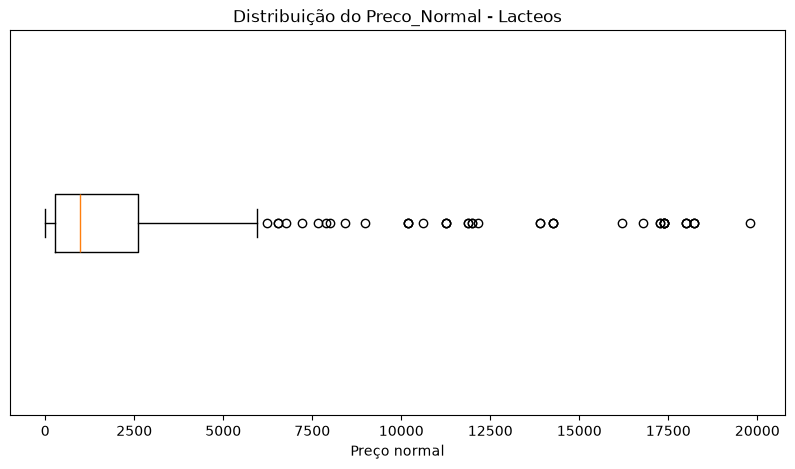

In [9]:
lacteos = df.loc[df['Categoria'] == 'lacteos']

plt.figure(figsize=(10, 5))
plt.boxplot(lacteos['Preco_Normal'], vert=False)
plt.title('Distribuição do Preco_Normal - Lacteos')
plt.xlabel('Preço normal')
plt.yticks([])
plt.savefig('graficos/boxplot_lacteos.png', dpi=120, bbox_inches='tight')
plt.show()

In [10]:
# calculando os limites do boxplot pra achar os outliers
q1 = lacteos['Preco_Normal'].quantile(0.25)
q3 = lacteos['Preco_Normal'].quantile(0.75)
iqr = q3 - q1
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

print('Q1:', q1)
print('Q3:', q3)
print('IQR:', iqr)
print('Limite inferior:', limite_inferior)
print('Limite superior:', limite_superior)

Q1: 269.0
Q3: 2609.0
IQR: 2340.0
Limite inferior: -3241.0
Limite superior: 6119.0


In [11]:
outliers = lacteos.loc[(lacteos['Preco_Normal'] > limite_superior) | (lacteos['Preco_Normal'] < limite_inferior)]
print('Quantidade de outliers:', len(outliers), 'de', len(lacteos), 'produtos')

outliers[['title', 'Marca', 'Preco_Normal']].sort_values('Preco_Normal', ascending=False)

Quantidade de outliers: 43 de 447 produtos


,title,Marca,Preco_Normal
0,"Pack 12 un, Leche extra proteína 1 L",Loncoleche,19788
1,"Pack 12 un, Leche chocolate receta original 1 L",Soprole,18228
2,"Pack 12 un, Leche semidescremada chocolate 1 L",Soprole,18228
3,"Pack 12 un, Leche semidescremada frutilla 1 L",Soprole,18228
4,"Pack 12 un, Leche sin lactosa chocolate 1 L",Loncoleche,17988
5,"Pack 12 un, Leche sin lactosa frutilla 1 L",Loncoleche,17988
6,"Pack 12 un, Leche saborizada light chocolate 1 L",Loncoleche,17988
7,"Pack 12 un, Leche saborizada frutilla 1 L",Colun,17388
8,"Pack 12 un, Leche saborizada vainilla 1 L",Colun,17388
9,"Pack 12 un, Leche saborizada manjar 1 L",Colun,17388


**Análise do boxplot:**

- A distribuição é bem **assimétrica à direita**: a caixa (Q1 = 269, Q3 = 2609) está concentrada nos preços baixos e o bigode da direita é bem mais comprido.
- A mediana (989) fica mais perto do Q1 do que do Q3, outra confirmação dessa assimetria.
- **Sim, tem muitos outliers**: 43 produtos acima do limite superior (≈ 6119) e nenhum abaixo do limite inferior (que é negativo).
- Olhando a lista, os outliers são basicamente **packs de 12 e 6 litros de leite** (Soprole, Colun, Loncoleche, Cuisine & Co) e **latas grandes de leite em pó** (Nido, Svelty). O mais caro é o pack de 12 de Leche extra proteína da Loncoleche (19788).
- Não são erros de cadastro: são produtos vendidos em quantidade maior, por isso o preço é bem mais alto. São eles que explicam o desvio padrão alto e a média muito acima da mediana.

# 4 - Plote um gráfico de barras onde temos a média de descontos por categoria.

In [12]:
media_desconto = df.groupby('Categoria')['Desconto'].mean().round(2).sort_values(ascending=False)
media_desconto

Categoria
congelados                    154.03
belleza-y-cuidado-personal    123.08
comidas-preparadas             43.48
lacteos                        17.41
frutas                          0.00
instantaneos-y-sopas            0.00
verduras                        0.00
Name: Desconto, dtype: float64

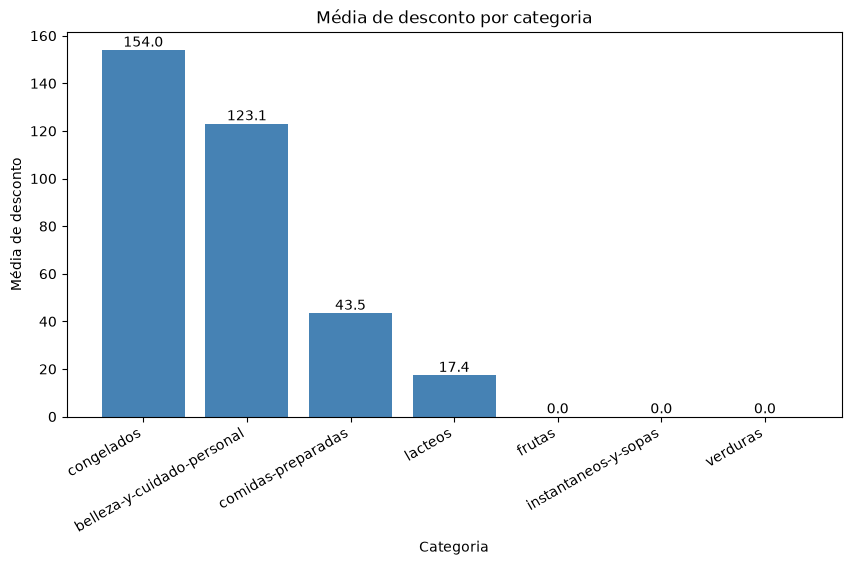

In [13]:
plt.figure(figsize=(10, 5))
barras = plt.bar(media_desconto.index, media_desconto.values, color='steelblue')
plt.bar_label(barras, fmt='%.1f')
plt.title('Média de desconto por categoria')
plt.xlabel('Categoria')
plt.ylabel('Média de desconto')
plt.xticks(rotation=30, ha='right')
plt.savefig('graficos/barras_media_desconto.png', dpi=120, bbox_inches='tight')
plt.show()

Congelados (≈ 154) e belleza-y-cuidado-personal (≈ 123) são as categorias com maior média de desconto. Frutas, verduras e instantaneos-y-sopas não tiveram nenhum produto com desconto, por isso a média é 0.

Vale lembrar que a média considera todos os produtos (inclusive os que têm desconto 0), então ela reflete tanto o tamanho do desconto quanto a quantidade de produtos em promoção.

# 5 - Plote um gráfico de mapa interativo agrupando os dados por categoria, marca e trazendo a média de desconto.

In [14]:
desconto_marca = df.groupby(['Categoria', 'Marca']).agg(
    media_desconto=('Desconto', 'mean'),
    qtd_produtos=('title', 'count')
).reset_index()

desconto_marca.sort_values('media_desconto', ascending=False).head(10)

,Categoria,Marca,media_desconto,qtd_produtos
78,congelados,Magnum,955.000000,4
142,lacteos,Nido,869.800000,5
39,belleza-y-cuidado-personal,Oral Fresh,797.000000,1
48,belleza-y-cuidado-personal,Rexona Men Clinical,795.000000,1
46,belleza-y-cuidado-personal,Rexona Clinical,795.000000,2
41,belleza-y-cuidado-personal,Pantene,684.857143,7
45,belleza-y-cuidado-personal,Rexona,660.000000,1
47,belleza-y-cuidado-personal,Rexona Men,660.000000,1
79,congelados,Mega,657.000000,1
6,belleza-y-cuidado-personal,BiO,650.000000,4


In [15]:
# mapa de árvore (treemap): o tamanho é a quantidade de produtos e a cor é a média de desconto
fig = px.treemap(
    desconto_marca,
    path=[px.Constant('Todas as categorias'), 'Categoria', 'Marca'],
    values='qtd_produtos',
    color='media_desconto',
    color_continuous_scale='RdYlGn',
    hover_data={'media_desconto': ':.2f'},
    title='Média de desconto por categoria e marca'
)
fig.update_layout(margin=dict(t=50, l=10, r=10, b=10))
fig.write_html('graficos/mapa_desconto.html')
fig.write_image('graficos/mapa_desconto.png', width=1400, height=800)
fig.show()

No mapa dá pra clicar em cada categoria pra ver as marcas dentro dela. O tamanho de cada bloco é a quantidade de produtos e a cor é a média de desconto (verde = mais desconto).

Dá pra ver que os descontos se concentram em algumas marcas de congelados e de belleza-y-cuidado-personal, enquanto lacteos, mesmo sendo a maior categoria, quase não tem desconto.